# epi_caf_invasion_PDAC

PhysiCell's `published/grammar_samples/user_projects/epi_caf_invasion/config/PhysiCell_settings_PDAC.xml` as a **self-contained notebook**. The model below is Python,
generated from that project's XML and rules CSV; nothing here reads a PhysiCell
file, builds an executable or parses an output folder.

| | |
|---|---|
| domain | 80 x 80 x 1 voxels, dx=20 um, 2D |
| substrates | inflammatory_signal, ecm |
| cell types | epithelial_normal, mesenchymal_normal, fibroblast, epithelial_tumor, mesenchymal_tumor, other_tissue |
| rules | 12 (12 runnable here) |
| initial cells | 3983, from `data/epi_caf_invasion_PDAC_cells.csv` |

**Sections 3 to 7 are the point of the library**: each one is something the
XML-and-executable workflow cannot do at all, or can only do by editing C++,
recompiling and re-running from t=0.


In [1]:
import pathlib
import numpy as np, matplotlib.pyplot as plt
import pyphysicell as pc
from pyphysicell import viz

# the data this notebook needs sits next to it
DATA = next(p for p in (pathlib.Path('data'), pathlib.Path('notebooks/data'))
            if p.exists())
print('kernels:', pc.BACKEND, '|', pc.MAX_THREADS, 'threads', '| data:', DATA)

kernels: std::thread | 2 threads | data: data


## 1. The model is an object

Not a document to be parsed at start-up: a value you can read, edit, copy, hash
and generate. Everything below came from the project's XML.

In [2]:
# Generated by pyphysicell.codegen from published/grammar_samples/user_projects/epi_caf_invasion/config/PhysiCell_settings_PDAC.xml.
# Values are PhysiCell's: minutes, microns, and each substrate's own units.


model = pc.Model(name="epi_caf_invasion")
model.domain = pc.Domain(x_min=-800.0, x_max=800.0, y_min=-800.0, y_max=800.0, z_min=-10.0, z_max=10.0, dx=20.0, dy=20.0, dz=20.0, use_2D=True)
model.time = pc.Time(dt_diffusion=0.01, dt_mechanics=0.1, dt_phenotype=6.0, max_time=21600.0, time_units="min", space_units="micron")
model.random_seed = 0
model.virtual_wall = True
model.omp_num_threads = 8
model.calculate_gradients = True
model.track_internalized_substrates = False
model.disable_automated_spring_adhesions = False
model.legacy_division_orientation = False
model.save = pc.SaveOptions(folder="outputs/epi_caf_invasion/PDAC", full_interval=30.0, full_enabled=True, svg_interval=30.0, svg_enabled=True)

# --- substrates --------------------------------------------------------------
model.substrates = [
    pc.Substrate(
        "inflammatory_signal",
        diffusion_coefficient=100.0,
        decay_rate=0.01,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
    pc.Substrate(
        "ecm",
        diffusion_coefficient=0.0,
        decay_rate=0.0,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
]

# --- cell types --------------------------------------------------------------
ct0 = pc.CellType("epithelial_normal", ID=0)
ct0.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct0.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=5.31667e-05,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct0.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct0.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct0.motility = pc.Motility(speed=0.0, persistence_time=1.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct0.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0)}
ct0.custom_data = {"sample": 1.0}
ct0.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.0, "fibroblast": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    immunogenicities={})
ct0.custom_conserved = {"sample": False}

ct1 = pc.CellType("mesenchymal_normal", ID=1)
ct1.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct1.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=5.31667e-06,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct1.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct1.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.1, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct1.motility = pc.Motility(speed=0.249908679, persistence_time=10.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct1.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=1.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0)}
ct1.custom_data = {"sample": 1.0}
ct1.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.01, "fibroblast": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.001},
    immunogenicities={})
ct1.custom_conserved = {"sample": False}

ct2 = pc.CellType("fibroblast", ID=2)
ct2.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct2.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct2.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct2.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct2.motility = pc.Motility(speed=8.03971290256818e-06, persistence_time=10.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct2.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.1, secretion_target=10.0, uptake_rate=0.0, net_export_rate=0.0)}
ct2.custom_data = {"sample": 1.0}
ct2.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.0, "fibroblast": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    immunogenicities={})
ct2.custom_conserved = {"sample": False}

ct3 = pc.CellType("epithelial_tumor", ID=3)
ct3.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.001},
         fixed_duration={(0, 0): False})
ct3.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=5.31667e-05,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct3.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct3.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct3.motility = pc.Motility(speed=0.0, persistence_time=1.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct3.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0)}
ct3.custom_data = {"sample": 1.0}
ct3.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.0, "fibroblast": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    immunogenicities={})
ct3.custom_conserved = {"sample": False}

ct4 = pc.CellType("mesenchymal_tumor", ID=4)
ct4.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct4.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=5.31667e-06,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct4.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct4.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.1, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct4.motility = pc.Motility(speed=0.249908679, persistence_time=10.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct4.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=1.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0)}
ct4.custom_data = {"sample": 1.0}
ct4.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.0, "fibroblast": 0.0, "epithelial_tumor": 0.01, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    immunogenicities={})
ct4.custom_conserved = {"sample": False}

ct5 = pc.CellType("other_tissue", ID=5)
ct5.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct5.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct5.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct5.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"fibroblast": 1.0, "epithelial_normal": 1.0, "epithelial_tumor": 1.0, "mesenchymal_normal": 1.0, "mesenchymal_tumor": 1.0})
ct5.motility = pc.Motility(speed=0.0, persistence_time=1.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="inflammatory_signal", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"inflammatory_signal": 0.0, "ecm": 0.0})
ct5.secretion = {
    "inflammatory_signal": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "ecm": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0)}
ct5.custom_data = {"sample": 1.0}
ct5.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    attack_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    fusion_rates={"fibroblast": 0.0, "epithelial_normal": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    transformation_rates={"epithelial_normal": 0.0, "fibroblast": 0.0, "epithelial_tumor": 0.0, "mesenchymal_normal": 0.0, "mesenchymal_tumor": 0.0},
    immunogenicities={})
ct5.custom_conserved = {"sample": False}

model.cell_types = [ct0, ct1, ct2, ct3, ct4, ct5]

model.user_parameters = {"number_of_cells": 0}

# --- rules (cell behavior hypothesis grammar) ---------------------------------
model.rules = [
    pc.Rule("epithelial_normal", "pressure", "decreases", "cycle entry", max_response=0.0, half_max=0.5, hill_power=4.0, apply_to_dead=False),
    pc.Rule("epithelial_tumor", "pressure", "decreases", "cycle entry", max_response=0.0, half_max=1.0, hill_power=4.0, apply_to_dead=False),
    pc.Rule("epithelial_normal", "ecm", "increases", "transform to mesenchymal_normal", max_response=0.01, half_max=0.01, hill_power=4.0, apply_to_dead=False),
    pc.Rule("epithelial_tumor", "ecm", "increases", "transform to mesenchymal_tumor", max_response=0.01, half_max=0.01, hill_power=4.0, apply_to_dead=False),
    pc.Rule("mesenchymal_normal", "ecm", "decreases", "migration speed", max_response=0.249678089, half_max=0.059591632, hill_power=1.224134673, apply_to_dead=False),
    pc.Rule("mesenchymal_normal", "ecm", "increases", "migration speed", max_response=3.78565306, half_max=3.119412867, hill_power=9.998145256, apply_to_dead=False),
    pc.Rule("mesenchymal_tumor", "ecm", "decreases", "migration speed", max_response=0.249678089, half_max=0.059591632, hill_power=1.224134673, apply_to_dead=False),
    pc.Rule("mesenchymal_tumor", "ecm", "increases", "migration speed", max_response=3.78565306, half_max=3.119412867, hill_power=9.998145256, apply_to_dead=False),
    pc.Rule("mesenchymal_tumor", "inflammatory_signal", "decreases", "transform to epithelial_tumor", max_response=0.0, half_max=0.2, hill_power=4.0, apply_to_dead=False),
    pc.Rule("mesenchymal_normal", "inflammatory_signal", "decreases", "transform to epithelial_normal", max_response=0.0, half_max=0.2, hill_power=4.0, apply_to_dead=False),
    pc.Rule("fibroblast", "ecm", "decreases", "migration speed", max_response=6.90516270388402e-06, half_max=2.078329369, hill_power=1.155103841, apply_to_dead=False),
    pc.Rule("fibroblast", "ecm", "increases", "migration speed", max_response=3.470551875, half_max=9.999679617, hill_power=1.153017946, apply_to_dead=False),
]

# --- initial conditions ------------------------------------------------------
# Initial conditions live beside this notebook (912 fibroblast, 2972 other_tissue, 59 epithelial_tumor, 37 mesenchymal_tumor, 2 epithelial_normal, 1 mesenchymal_normal).
CELLS = DATA / 'epi_caf_invasion_PDAC_cells.csv'
model.initial_cells = pc.read_cells_csv(CELLS, model.cell_type_names)
print(f'{len(model.initial_cells)} cells from {CELLS.name}')

3983 cells from epi_caf_invasion_PDAC_cells.csv


In [3]:
print(model.summary())
print('content hash:', model.hash, '-- changes with any edit, so runs are traceable')

model 'epi_caf_invasion'  [80033bc3e06b]
  domain     80 x 80 x 1 voxels, dx=20 um, 2D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=21600 min
  substrates inflammatory_signal, ecm
  cell types epithelial_normal, mesenchymal_normal, fibroblast, epithelial_tumor, mesenchymal_tumor, other_tissue
  rules      12
  initial    3983 cells
content hash: 80033bc3e06b -- changes with any edit, so runs are traceable


## 2. Answers before you simulate

These cost milliseconds and need no run at all. `check()` is dimensional analysis
of the model as written; the cycle duration is closed-form from the phase graph;
a rule's response curve is a pure function of its signal.

In [4]:
print(pc.check(model))

check: 'epi_caf_invasion' [80033bc3e06b]
  [marginal] inflammatory_signal        L=sqrt(D/lambda)=   100.0 um =   5.0 dx
  [WARN] ecm                        D=0, lambda=0; no decay: no steady length scale, spreads ~0 um per day
  [info    ] epithelial_normal          does not cycle on its own (rate 0; a rule may drive it)
  [info    ] mesenchymal_normal         does not cycle on its own (rate 0; a rule may drive it)
  [info    ] fibroblast                 does not cycle on its own (rate 0; a rule may drive it)
  [info    ] epithelial_tumor           cycle mean duration 16.7 h (from the phase graph, no simulation)
  [info    ] mesenchymal_tumor          does not cycle on its own (rate 0; a rule may drive it)
  [info    ] other_tissue               does not cycle on its own (rate 0; a rule may drive it)
  [info    ] mesh 80x80x1 = 6400 voxels, 0.1 MB of field per saved snapshot
  [info    ] 2160000 diffusion steps to reach max_time=21600 min


In [5]:
for ct in model.cell_types:
    d = ct.cycle.mean_duration()
    print(f'{ct.name:<28} cycle {d/60:8.1f} h' if np.isfinite(d)
          else f'{ct.name:<28} does not cycle on its own')

epithelial_normal            does not cycle on its own
mesenchymal_normal           does not cycle on its own
fibroblast                   does not cycle on its own
epithelial_tumor             cycle     16.7 h
mesenchymal_tumor            does not cycle on its own
other_tissue                 does not cycle on its own


In epithelial_normal cells, pressure decreases cycle entry towards 0 with half-max 0.5 and Hill power 4.
In epithelial_tumor cells, pressure decreases cycle entry towards 0 with half-max 1 and Hill power 4.
In epithelial_normal cells, ecm increases transform to mesenchymal_normal towards 0.01 with half-max 0.01 and Hill power 4.


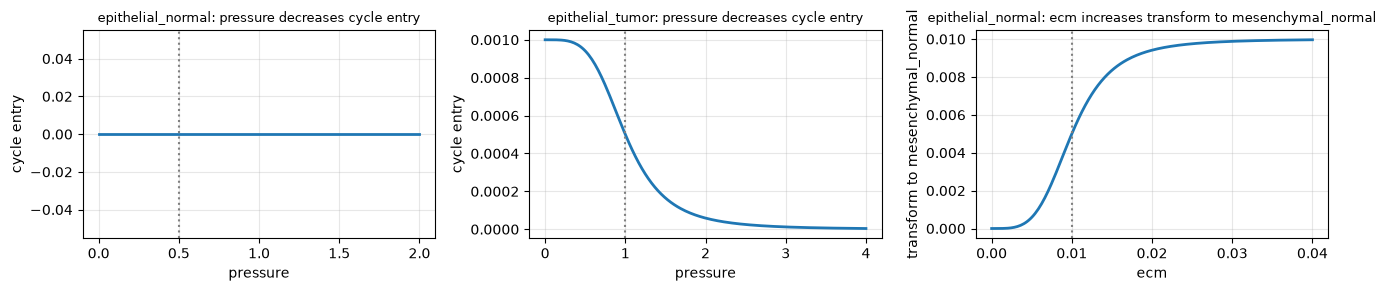

In [6]:
d = pc.Dictionary(model)
shown = [r for r in model.rules if d.supports_signal(r.signal)
         and d.supports_behavior(r.behavior)][:3]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 3))
for ax, r in zip(np.atleast_1d(axes), shown):
    viz.plot_rule(r, d.base_behavior(r.cell_type, r.behavior), ax=ax)
    print(r.english())
plt.tight_layout()

## 3. Run it, and keep the simulation

`sim` stays alive afterwards: its cells and fields are NumPy arrays you can read
and change, and the run can be continued. The executable exits and leaves files.

This demo covers 290.46 min. One turn of this model's fastest cycle is 1000 min and its own config asks for 21600 min, so what follows is a smoke test of the machinery, not a result: at this window the population cannot divide.

In [7]:
sim = pc.Simulation(model, seed=model.random_seed)
if not sim.cells.n:
    print(pc.initial.apply(sim))
scalars = sim.run(until=290.46, record_every=24.205)
print(sim, f'| {sim.wall_time:.1f} s')
sim.dataframe().head(3)

<Simulation 'epi_caf_invasion' t=290.5 min cells=4001 backend=std::thread:2> | 15.9 s


,ID,x,y,z,type,volume,radius,phase,dead,pressure,cell_type
0,0,114.378965,-334.422635,0.0,2,2494.0,8.412711,0,False,0.515861,fibroblast
1,1,14.127346,416.717722,0.0,5,2494.0,8.412711,0,False,0.291757,other_tissue
2,2,71.310657,384.740193,0.0,5,2494.0,8.412711,0,False,0.243963,other_tissue


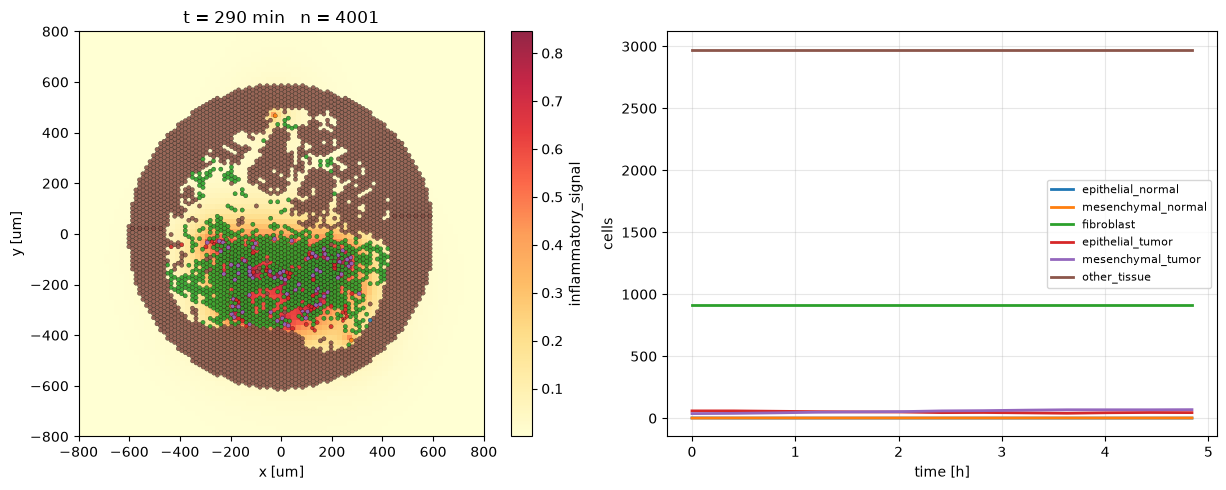

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_cells(sim, substrate='inflammatory_signal', ax=axes[0])
viz.plot_populations(scalars, ax=axes[1])
plt.tight_layout()

## 4. Steer it while it runs

Change the state mid-run and carry on from where you are. In the file workflow
this is a new XML and a new run from t=0, or custom C++ and a recompile.

mean inflammatory_signal 0.0818 -> 0.0862


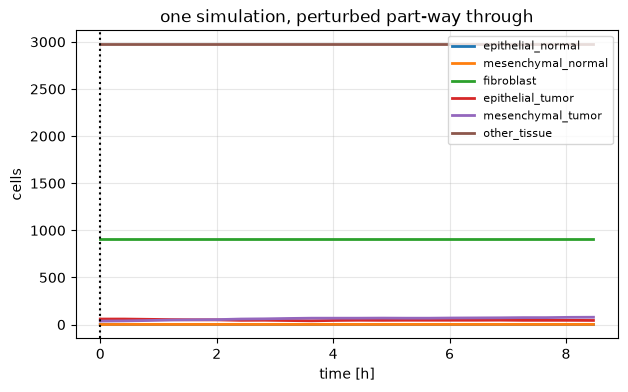

In [9]:
before = sim.microenvironment['inflammatory_signal'].mean()
sim.microenvironment.density[..., 0] = 0.0      # remove inflammatory_signal everywhere
sim.run(until=sim.t + 217.84, record_every=24.205)
print(f'mean inflammatory_signal {before:.3g} -> {sim.microenvironment['inflammatory_signal'].mean():.3g}')
viz.plot_populations(sim.scalars)
plt.axvline(sim.scalars.times[0] / 60, ls=':', c='k')
plt.title('one simulation, perturbed part-way through');

## 5. Two futures from one state

`branch()` is a deepcopy of the whole simulation, because all of the state is
Python. PhysiCell keeps its state in process globals, so a second simulation in
the same process is impossible there and a counterfactual means re-running from
the beginning with a different input file.

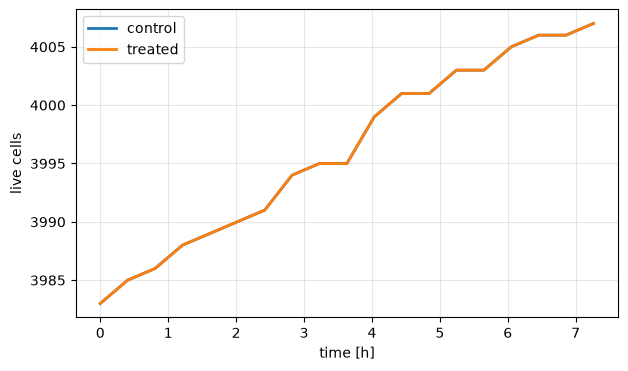

In [10]:
base = pc.Simulation(model, seed=model.random_seed)
if not base.cells.n:
    pc.initial.apply(base)
base.run(until=217.84, record_every=24.205)

control = base.branch()
treated = base.branch()
treated.microenvironment.density[..., 0] *= 0.1   # 90% knock-down
control.run(until=control.t + 217.84, record_every=24.205)
treated.run(until=treated.t + 217.84, record_every=24.205)

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in (('control', control.scalars), ('treated', treated.scalars)):
    total = np.sum([v for v in s.counts.values()], axis=0)
    ax.plot(np.asarray(s.times) / 60, total, lw=2, label=name)
ax.set_xlabel('time [h]'); ax.set_ylabel('live cells'); ax.legend(); ax.grid(alpha=0.3);

## 6. Logic the rules grammar cannot express

A CBHG rule is a Hill function of one cell's own signals: it cannot see where a
cell is, or how it ranks against the rest of the population. A hook is arbitrary
Python over the whole population, called once per phenotype step on arrays, so
both become possible -- and still no C++.

In [11]:
probe = pc.Simulation(model, seed=model.random_seed)
if not probe.cells.n:
    pc.initial.apply(probe)
log = []

@probe.hook('phenotype', cell_type='other_tissue')
def spatial_and_population_relative(ctx):
    p = ctx.signals['pressure']
    crowded = p >= np.quantile(p, 0.9) if ctx.n > 1 else np.zeros(ctx.n, bool)
    left = ctx.position[:, 0] < 0
    # population-relative: the most crowded tenth stops cycling
    ctx.behaviors['cycle entry'] = np.where(crowded, 0.0,
                                            ctx.behaviors['cycle entry'])
    # spatial: cells in the left half of the domain stop migrating
    ctx.behaviors['migration speed'] = np.where(left, 0.0,
                                                ctx.behaviors['migration speed'])
    log.append((ctx.t, int(crowded.sum()), float(left.mean())))

probe.run(until=217.84, record_every=24.205)
c = probe.cells
mine = c.view('type_idx') == probe.type_index['other_tissue']
left = mine & (c.view('position')[:, 0] < 0)
right = mine & (c.view('position')[:, 0] >= 0)
print(f'hook fired {len(log)} times, one call per phenotype step for all {mine.sum()} cells')
print(f"  mean migration speed   left {c.view('motility_speed')[left].mean():.3f}   right {c.view('motility_speed')[right].mean():.3f}")
print(f"  mean cycle entry rate  crowded decile is held at 0; population mean {c.view('cycle_entry_rate')[mine].mean():.3e}")

hook fired 37 times, one call per phenotype step for all 2972 cells
  mean migration speed   left 0.000   right 0.000
  mean cycle entry rate  crowded decile is held at 0; population mean 0.000e+00


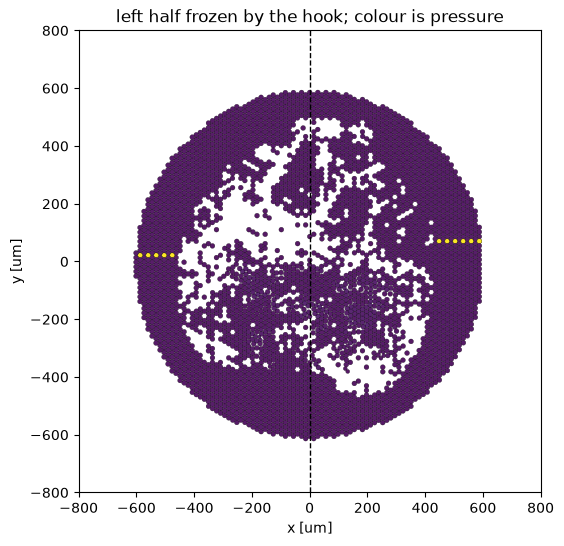

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_cells(probe, color_by='pressure', ax=ax)
ax.axvline(0, ls='--', c='k', lw=1)
ax.set_title('left half frozen by the hook; colour is pressure');

## 7. A sweep in one process

Varying the decay rate of inflammatory_signal, with replicates. No files, no subprocesses, no recompilation --
the models and the simulations are objects, so N of them are just N objects.

*That parameter was not chosen by hand.* The generator screened every knob this
model exposes -- rule half-maxes and saturated responses, cycle and death rates,
migration speed, substrate decay -- at half and double its published value, and
kept the one that moved an outcome most (200% spread at x4). Most knobs
in a
published model move nothing at its own parameters, which is itself worth
knowing before you spend a cluster on a sweep.

In [13]:
def change(m, value):
    m.substrate('inflammatory_signal').decay_rate = value

df, runs = pc.sweep(model, change, [0.0025, 0.01, 0.04], until=217.84,
                    replicates=2, progress=True)
df[['value', 'replicate', 'cells', 'births', 'deaths', 'spread_um',
    'mean_pressure', 'wall_s']]

        0.0025  rep 0  ->    3994 cells (15.9 s)


        0.0025  rep 1  ->    3988 cells (15.8 s)


          0.01  rep 0  ->    3991 cells (16.0 s)


          0.01  rep 1  ->    3992 cells (16.9 s)


          0.04  rep 0  ->    3995 cells (17.2 s)


          0.04  rep 1  ->    3996 cells (17.2 s)


,value,replicate,cells,births,deaths,spread_um,mean_pressure,wall_s
0,0.0025,0,3994,11,1,448.64,0.6201,15.94
1,0.0025,1,3988,5,1,448.81,0.6237,15.76
2,0.0100,0,3991,8,0,448.71,0.6228,16.00
3,0.0100,1,3992,9,1,448.66,0.6211,16.89
4,0.0400,0,3995,12,1,448.50,0.6318,17.15
5,0.0400,1,3996,13,0,448.53,0.6319,17.22


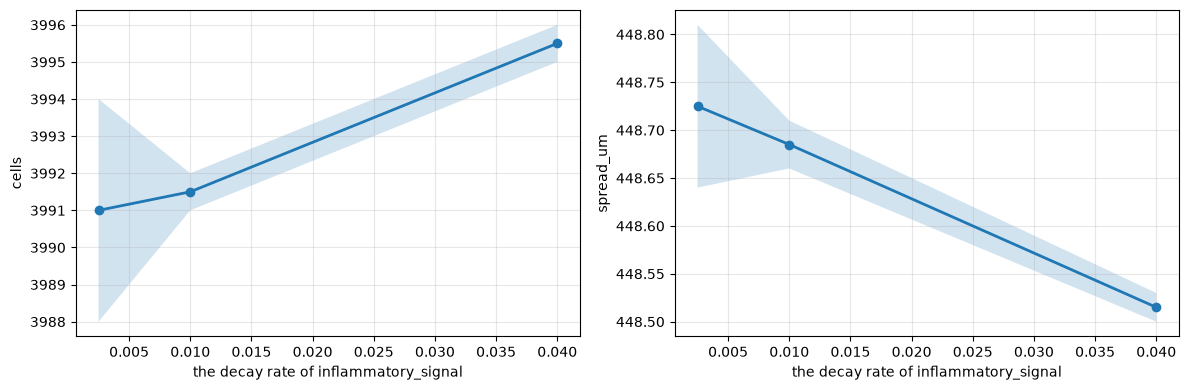

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pc.plot_sweep(df, 'cells', ax=axes[0], label='live cells')
pc.plot_sweep(df, 'spread_um', ax=axes[1], label='spread (RMS radius)')
axes[0].set_xlabel('the decay rate of inflammatory_signal'); axes[1].set_xlabel('the decay rate of inflammatory_signal')
plt.tight_layout()

## 8. Stop when something happens

A question like *when* does this model cross a level is a stopping condition
here, and a post-hoc search through saved snapshots otherwise.

The level is read off the run in section 3 rather than guessed, so the condition
is an event this model really reaches. An earlier version of this notebook picked
a threshold a priori and ran to its limit in 19 of 37 projects, demonstrating
nothing.

In [15]:
import numpy as np
h = sim.scalars
t = np.asarray(h.times, dtype=float)
# sections 4-6 steered this same sim, so calibrate on the untouched part
keep = t <= 290.46
t = t[keep]
series = {}
if h.counts:
    series['live cells'] = np.asarray([sum(v) for v in zip(*h.counts.values())],
                                      dtype=float)[keep]
series['dead cells'] = np.asarray(h.dead, dtype=float)[keep]
series['cumulative births'] = np.asarray(h.births, dtype=float)[keep]
series['cumulative deaths'] = np.asarray(h.deaths, dtype=float)[keep]
for _s, _v in h.mean_substrate.items():
    series[f'mean {_s}'] = np.asarray(_v, dtype=float)[keep]

def moved(v):
    scale = max(float(np.abs(v).max()), 1e-12)
    return max(abs(v[-1] - v[0]), v.max() - v.min()) / scale

name, y = max(series.items(), key=lambda kv: moved(kv[1]))
y0, lo, hi, end = float(y[0]), float(y.min()), float(y.max()), float(y[-1])
if end != y0:                      # 60% of the way to where it ended
    rising, level = end > y0, y0 + 0.6 * (end - y0)
else:                              # it came back: aim at the far extreme
    rising = (hi - y0) >= (y0 - lo)
    level = y0 + 0.6 * ((hi - y0) if rising else (lo - y0))
live = moved(y) > 0
print(f'{sum(moved(v) > 0 for v in series.values())} of {len(series)} recorded observables moved')
if live:
    crossed = t[np.argmax((y >= level) if rising else (y <= level))]
    print(f'watching {name}: the baseline crossed {level:.4g} at t = {crossed:.1f} min')
else:
    print('nothing this model records changes over the demo window')

4 of 6 recorded observables moved
watching cumulative births: the baseline crossed 10.8 at t = 169.4 min


In [16]:
readers = {'live cells': lambda s: float((s.cells.view('dead') == 0).sum()),
           'dead cells': lambda s: float((s.cells.view('dead') == 1).sum()),
           'cumulative births': lambda s: float(s._births),
           'cumulative deaths': lambda s: float(s._deaths)}
for _s in model.substrate_names:
    readers[f'mean {_s}'] = (lambda n: lambda s: float(s.microenvironment[n].mean()))(_s)
read = readers[name]

watch = pc.Simulation(model, seed=model.random_seed)
if not watch.cells.n:
    pc.initial.apply(watch)
limit = 1161.84
watch.run(until=limit, record_every=24.205,
          stop_when=(lambda s: (read(s) >= level) if rising else (read(s) <= level))
                    if live else None)
print(f'stopped at t = {watch.t:.1f} min of a {limit:.0f} min limit, {name} = {read(watch):.4g}')
if live:
    assert watch.t < limit, 'the stopping condition never fired'

stopped at t = 168.0 min of a 1162 min limit, cumulative births = 11
